# Step Line Chart

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

A line that moves in horizontal and vertical steps instead of diagonals. It shows that a value holds constant between changes, as with policy rates, prices, or inventory levels.

## When to use

- Show values that change at discrete moments and stay flat in between (interest rates, tariffs, headcount)
- Make the timing and size of each change visible

## Avoid when

- The quantity varies continuously (a sloped line is more honest)

## Alternatives

- Line chart
- Event timeline

## Design tips

- Use where='post' when the value takes effect at the change date

## Example

Central bank policy rate decisions, 2019–2025, synthetic data.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
df = pd.DataFrame({
    "date": pd.to_datetime(["2019-01-01", "2019-08-01", "2019-10-30", "2020-03-03", "2020-03-15",
                            "2022-03-16", "2022-05-04", "2022-06-15", "2022-07-27", "2022-09-21",
                            "2022-11-02", "2022-12-14", "2023-02-01", "2023-03-22", "2023-05-03",
                            "2023-07-26", "2024-09-18", "2024-11-07", "2024-12-18", "2025-06-30"]),
    "rate": [2.50, 2.25, 1.75, 1.25, 0.25, 0.50, 1.00, 1.75, 2.50, 3.25,
             4.00, 4.50, 4.75, 5.00, 5.25, 5.50, 5.00, 4.75, 4.50, 4.50],
})
df.head()

,date,rate
0,2019-01-01,2.50
1,2019-08-01,2.25
2,2019-10-30,1.75
3,2020-03-03,1.25
4,2020-03-15,0.25


### Plot

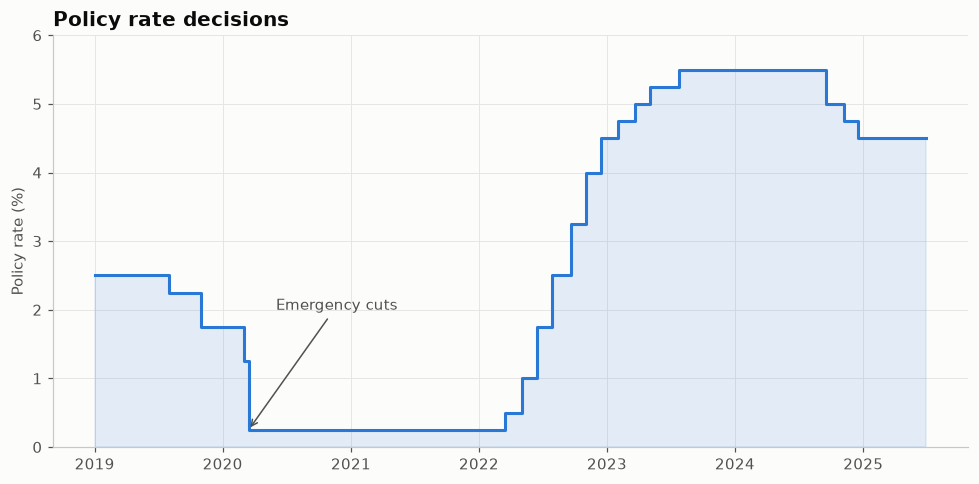

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.step(df["date"], df["rate"], where="post", color=PALETTE[0])
ax.fill_between(df["date"], df["rate"], step="post", color=PALETTE[0], alpha=0.12)
ax.set_ylim(0, 6)
ax.set_ylabel("Policy rate (%)")
ax.set_title("Policy rate decisions")
ax.annotate("Emergency cuts", xy=(pd.Timestamp("2020-03-15"), 0.25),
            xytext=(pd.Timestamp("2020-06-01"), 2.0), color="#52514e",
            arrowprops=dict(arrowstyle="->", color="#52514e"))
fig.tight_layout()
plt.show()

---
Standalone script: [`step_line.py`](step_line.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)